## 1. Install dependencies

In [1]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn mlflow fastapi "uvicorn[standard]" joblib pydantic pytest httpx

## 2. Imports and project folders

In [2]:
import os
import json
import shutil
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

PROJECT_DIR = Path("/content/kalamkari_drying_project")
DATA_DIR = PROJECT_DIR / "data"
FEATURE_DIR = PROJECT_DIR / "feature_store"
MODEL_DIR = PROJECT_DIR / "models"
APP_DIR = PROJECT_DIR / "serving"
TEST_DIR = PROJECT_DIR / "tests"
WORKFLOW_DIR = PROJECT_DIR / ".github" / "workflows"

for folder in [DATA_DIR, FEATURE_DIR, MODEL_DIR, APP_DIR, TEST_DIR, WORKFLOW_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: /content/kalamkari_drying_project


In [3]:
def generate_fabric_batches(n=300, version="v1", seed=42):
    local_rng = np.random.default_rng(seed)

    fabric_material = local_rng.choice(
        ["cotton", "silk"], size=n, p=[0.70, 0.30]
    )
    fabric_length_m = local_rng.uniform(2.0, 30.0, size=n).round(2)
    dye_coats = local_rng.integers(1, 6, size=n)

    if version == "v1":
        humidity_pct = local_rng.uniform(40, 74, size=n)
        ambient_temperature_c = local_rng.uniform(24, 38, size=n)
    elif version == "v2_monsoon":
        humidity_pct = local_rng.uniform(75, 95, size=n)
        ambient_temperature_c = local_rng.uniform(22, 32, size=n)
    else:
        raise ValueError("version must be 'v1' or 'v2_monsoon'")

    airflow_speed_mps = local_rng.uniform(0.05, 2.5, size=n)
    drying_rack_occupancy_pct = local_rng.uniform(10, 100, size=n)

    # Feature calculations used to create the synthetic target.
    moisture_load_index = (
        fabric_length_m * dye_coats * (humidity_pct / 100.0)
    )
    airflow_per_meter = airflow_speed_mps / fabric_length_m

    material_factor = np.where(fabric_material == "silk", 1.12, 1.0)
    occupancy_factor = 1.0 + (drying_rack_occupancy_pct / 100.0) * 0.30

    drying_hours = (
        1.2
        + 0.17 * moisture_load_index
        + 0.55 * (1.0 / (airflow_speed_mps + 0.15))
        + 0.035 * (35 - ambient_temperature_c)
        + 0.80 * occupancy_factor
    ) * material_factor

    # A small random component makes the prediction task more realistic.
    drying_hours += local_rng.normal(0, 0.65, size=n)
    drying_hours = np.clip(drying_hours, 0.5, None)

    return pd.DataFrame({
        "batch_id": [f"{version}_{i+1:04d}" for i in range(n)],
        "dataset_version": version,
        "fabric_material": fabric_material,
        "fabric_length_m": fabric_length_m,
        "dye_coats": dye_coats,
        "humidity_pct": humidity_pct.round(2),
        "ambient_temperature_c": ambient_temperature_c.round(2),
        "airflow_speed_mps": airflow_speed_mps.round(3),
        "drying_rack_occupancy_pct": drying_rack_occupancy_pct.round(2),
        "actual_drying_hours": drying_hours.round(2)
    })

v1_df = generate_fabric_batches(300, "v1", seed=42)
v2_df = generate_fabric_batches(300, "v2_monsoon", seed=2026)

v1_path = DATA_DIR / "fabric_batches_v1.csv"
v2_path = DATA_DIR / "fabric_batches_v2_monsoon.csv"
v1_df.to_csv(v1_path, index=False)
v2_df.to_csv(v2_path, index=False)

print("v1 records:", len(v1_df), "| humidity:", v1_df.humidity_pct.min(), "-", v1_df.humidity_pct.max())
print("v2 records:", len(v2_df), "| humidity:", v2_df.humidity_pct.min(), "-", v2_df.humidity_pct.max())
display(v1_df.head())
display(v2_df.head())

v1 records: 300 | humidity: 40.08 - 73.77
v2 records: 300 | humidity: 75.1 - 94.98


,batch_id,dataset_version,fabric_material,fabric_length_m,dye_coats,humidity_pct,ambient_temperature_c,airflow_speed_mps,drying_rack_occupancy_pct,actual_drying_hours
0,v1_0001,v1,silk,23.81,5,48.85,33.35,1.997,33.94,13.00
1,v1_0002,v1,cotton,5.77,3,50.96,25.81,2.102,34.67,4.17
2,v1_0003,v1,silk,17.01,5,48.24,27.85,0.747,32.93,11.20
3,v1_0004,v1,cotton,16.40,4,56.32,25.94,0.794,22.15,8.93
4,v1_0005,v1,cotton,26.01,4,63.23,27.97,2.192,94.94,14.18


,batch_id,dataset_version,fabric_material,fabric_length_m,dye_coats,humidity_pct,ambient_temperature_c,airflow_speed_mps,drying_rack_occupancy_pct,actual_drying_hours
0,v2_monsoon_0001,v2_monsoon,cotton,22.79,4,88.90,22.55,0.414,17.91,17.05
1,v2_monsoon_0002,v2_monsoon,cotton,11.40,3,78.22,25.51,0.680,98.64,8.20
2,v2_monsoon_0003,v2_monsoon,cotton,2.26,1,92.07,30.93,1.040,72.51,3.92
3,v2_monsoon_0004,v2_monsoon,cotton,16.93,4,79.62,27.87,0.615,99.74,12.86
4,v2_monsoon_0005,v2_monsoon,cotton,7.31,3,76.47,25.20,0.675,26.70,6.36


### 3.1 Validate and compare dataset versions

,records,mean_humidity,mean_drying_hours,min_drying_hours,max_drying_hours
dataset_version,,,,,
v1,300,56.87,7.78,1.96,20.50
v2_monsoon,300,85.57,10.68,2.57,27.84


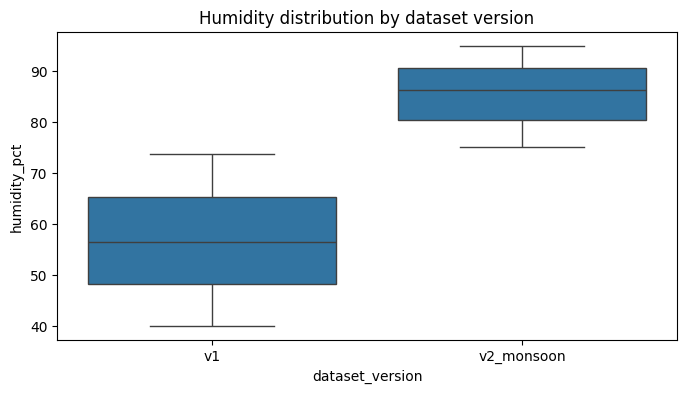

In [4]:
assert len(v1_df) >= 250 and len(v2_df) >= 250
assert v2_df["humidity_pct"].between(75, 95).all()
assert (v1_df["actual_drying_hours"] >= 0).all()
assert (v2_df["actual_drying_hours"] >= 0).all()

version_summary = pd.concat([v1_df, v2_df]).groupby("dataset_version").agg(
    records=("batch_id", "count"),
    mean_humidity=("humidity_pct", "mean"),
    mean_drying_hours=("actual_drying_hours", "mean"),
    min_drying_hours=("actual_drying_hours", "min"),
    max_drying_hours=("actual_drying_hours", "max")
).round(2)
display(version_summary)

plt.figure(figsize=(8, 4))
sns.boxplot(data=pd.concat([v1_df, v2_df]), x="dataset_version", y="humidity_pct")
plt.title("Humidity distribution by dataset version")
plt.show()

## 4. Data pipeline and feature store

Engineered features:

1. `moisture_load_index = fabric_length_m × dye_coats × (humidity_pct / 100)`
2. `airflow_per_meter = airflow_speed_mps / fabric_length_m`

The feature engineering is implemented as a scikit-learn transformer so that the exact same calculations are applied during training and prediction. The feature-store CSVs persist the engineered values for inspection and reuse.

In [5]:
# Put the custom transformer in a standalone module.
# The notebook and the separate Uvicorn process will import the same class.
feature_engineering_code = """
from sklearn.base import BaseEstimator, TransformerMixin

class KalamkariFeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["moisture_load_index"] = (
            X["fabric_length_m"] * X["dye_coats"] * X["humidity_pct"] / 100.0
        )
        X["airflow_per_meter"] = (
            X["airflow_speed_mps"] / X["fabric_length_m"].clip(lower=0.01)
        )
        return X
"""

feature_file = APP_DIR / "feature_engineering.py"
feature_file.write_text(feature_engineering_code)

import sys
import importlib
sys.path.insert(0, str(APP_DIR))
import feature_engineering
importlib.reload(feature_engineering)
from feature_engineering import KalamkariFeatureEngineer

print("Reusable transformer module created:", feature_file)

FEATURE_INPUTS = [
    "fabric_material", "fabric_length_m", "dye_coats", "humidity_pct",
    "ambient_temperature_c", "airflow_speed_mps",
    "drying_rack_occupancy_pct"
]
TARGET = "actual_drying_hours"

all_df = pd.concat([v1_df, v2_df], ignore_index=True)
feature_engineer = KalamkariFeatureEngineer()
engineered_df = feature_engineer.fit_transform(all_df[FEATURE_INPUTS])

feature_store_df = pd.concat(
    [all_df[["batch_id", "dataset_version"]].reset_index(drop=True),
     engineered_df.reset_index(drop=True),
     all_df[[TARGET]].reset_index(drop=True)],
    axis=1
)
feature_store_path = FEATURE_DIR / "kalamkari_feature_store_v1.csv"
feature_store_df.to_csv(feature_store_path, index=False)

feature_metadata = {
    "feature_store_version": "1.0",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "features": {
        "moisture_load_index": "fabric_length_m * dye_coats * humidity_pct / 100",
        "airflow_per_meter": "airflow_speed_mps / fabric_length_m"
    },
    "source_datasets": ["fabric_batches_v1.csv", "fabric_batches_v2_monsoon.csv"]
}
(FEATURE_DIR / "feature_metadata.json").write_text(json.dumps(feature_metadata, indent=2))
display(feature_store_df.head())
print("Saved feature store:", feature_store_path)

Reusable transformer module created: /content/kalamkari_drying_project/serving/feature_engineering.py


,batch_id,dataset_version,fabric_material,fabric_length_m,dye_coats,humidity_pct,ambient_temperature_c,airflow_speed_mps,drying_rack_occupancy_pct,moisture_load_index,airflow_per_meter,actual_drying_hours
0,v1_0001,v1,silk,23.81,5,48.85,33.35,1.997,33.94,58.155925,0.083872,13.00
1,v1_0002,v1,cotton,5.77,3,50.96,25.81,2.102,34.67,8.821176,0.364298,4.17
2,v1_0003,v1,silk,17.01,5,48.24,27.85,0.747,32.93,41.028120,0.043915,11.20
3,v1_0004,v1,cotton,16.40,4,56.32,25.94,0.794,22.15,36.945920,0.048415,8.93
4,v1_0005,v1,cotton,26.01,4,63.23,27.97,2.192,94.94,65.784492,0.084275,14.18


Saved feature store: /content/kalamkari_drying_project/feature_store/kalamkari_feature_store_v1.csv


## 5. Train/test split and preprocessing

In [6]:
X = all_df[FEATURE_INPUTS].copy()
y = all_df[TARGET].astype(float).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_features = [
    "fabric_length_m", "dye_coats", "humidity_pct",
    "ambient_temperature_c", "airflow_speed_mps",
    "drying_rack_occupancy_pct", "moisture_load_index",
    "airflow_per_meter"
]
categorical_features = ["fabric_material"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

def make_model_pipeline(regressor):
    return Pipeline(steps=[
        ("feature_engineering", KalamkariFeatureEngineer()),
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

print("Training records:", len(X_train), "| Test records:", len(X_test))

Training records: 480 | Test records: 120


## 6. Train Ridge Regression and Random Forest Regression

In [7]:
models = {
    "Ridge Regression": make_model_pipeline(Ridge(alpha=1.0)),
    "Random Forest Regression": make_model_pipeline(
        RandomForestRegressor(
            n_estimators=300,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
}

results = []
trained_models = {}

for model_name, model_pipeline in models.items():
    model_pipeline.fit(X_train, y_train)
    predictions = np.maximum(model_pipeline.predict(X_test), 0)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "model": model_name,
        "MAE_hours": mae,
        "RMSE_hours": rmse,
        "R2": r2
    })
    trained_models[model_name] = model_pipeline

metrics_df = pd.DataFrame(results).sort_values("MAE_hours").reset_index(drop=True)
display(metrics_df.round(4))

,model,MAE_hours,RMSE_hours,R2
0,Ridge Regression,0.5301,0.6621,0.9823
1,Random Forest Regression,0.5706,0.7775,0.9756


### 6.1 Compare models and select the best model

Selected model: Ridge Regression
MAE:  0.530 hours
RMSE: 0.662 hours
R²:   0.982


<Figure size 800x400 with 0 Axes>

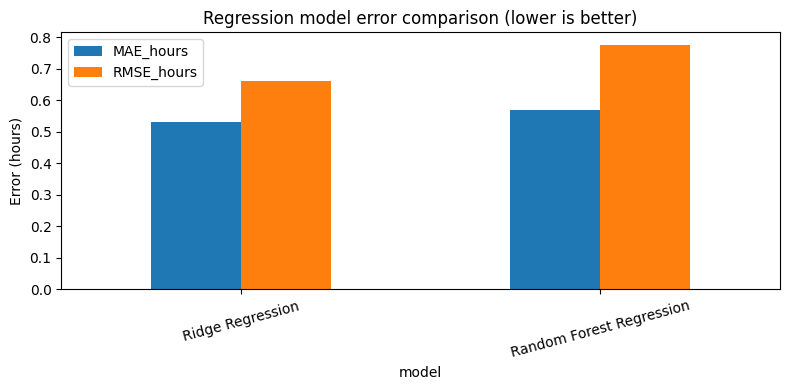

In [8]:
# Primary selection criterion: lowest MAE; RMSE breaks a tie.
best_model_name = metrics_df.sort_values(
    ["MAE_hours", "RMSE_hours"], ascending=True
).iloc[0]["model"]
best_model = trained_models[best_model_name]
best_row = metrics_df.loc[metrics_df["model"] == best_model_name].iloc[0]

print("Selected model:", best_model_name)
print(f"MAE:  {best_row['MAE_hours']:.3f} hours")
print(f"RMSE: {best_row['RMSE_hours']:.3f} hours")
print(f"R²:   {best_row['R2']:.3f}")

plt.figure(figsize=(8, 4))
metrics_df.set_index("model")[["MAE_hours", "RMSE_hours"]].plot(kind="bar", figsize=(8, 4))
plt.ylabel("Error (hours)")
plt.title("Regression model error comparison (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 7. Evaluate the selected model specifically on monsoon records

This is a useful seasonal check. The monsoon subset is kept separate from the overall random test split for a clear view of performance under high humidity. The model has seen monsoon records during training because both dataset versions are combined for training; this is a **monsoon holdout evaluation**, not a fully unseen-season test.

In [9]:
monsoon_mask = all_df["dataset_version"].eq("v2_monsoon")
X_monsoon = all_df.loc[monsoon_mask, FEATURE_INPUTS]
y_monsoon = all_df.loc[monsoon_mask, TARGET]
X_monsoon_train, X_monsoon_test, y_monsoon_train, y_monsoon_test = train_test_split(
    X_monsoon, y_monsoon, test_size=0.20, random_state=RANDOM_STATE
)
monsoon_pred = np.maximum(best_model.predict(X_monsoon_test), 0)

print("Monsoon test MAE:", round(mean_absolute_error(y_monsoon_test, monsoon_pred), 3), "hours")
print("Monsoon test RMSE:", round(np.sqrt(mean_squared_error(y_monsoon_test, monsoon_pred)), 3), "hours")
print("Monsoon test R²:", round(r2_score(y_monsoon_test, monsoon_pred), 3))

Monsoon test MAE: 0.544 hours
Monsoon test RMSE: 0.678 hours
Monsoon test R²: 0.983


## 8. MLflow experiment tracking and model registry

MLflow records parameters and evaluation metrics for both candidates. The model with the lower MAE is registered as `KalamkariDryingTimeModel`. This notebook uses a local SQLite tracking/registry backend, which is convenient for a Colab experiment. The MLflow database and artifacts are stored inside the project folder.

In [10]:
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

MLFLOW_DIR = PROJECT_DIR / "mlflow"
MLFLOW_DIR.mkdir(exist_ok=True)
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DIR / 'mlflow.db'}")
mlflow.set_registry_uri(f"sqlite:///{MLFLOW_DIR / 'mlflow.db'}")
mlflow.set_experiment("Kalamkari-Drying-Time-Estimation")

# Log both candidate pipelines using cloudpickle serialization.
for model_name, model_pipeline in trained_models.items():
    row = metrics_df.loc[metrics_df["model"] == model_name].iloc[0]
    with mlflow.start_run(run_name=model_name):
        mlflow.log_param("model_name", model_name)
        mlflow.log_param("training_rows", len(X_train))
        mlflow.log_param("dataset_versions", "v1,v2_monsoon")
        mlflow.log_metric("MAE_hours", float(row["MAE_hours"]))
        mlflow.log_metric("RMSE_hours", float(row["RMSE_hours"]))
        mlflow.log_metric("R2", float(row["R2"]))
        if model_name == "Ridge Regression":
            mlflow.log_param("alpha", 1.0)
        else:
            mlflow.log_param("n_estimators", 300)

        signature = infer_signature(X_train, model_pipeline.predict(X_train))
        mlflow.sklearn.log_model(
            sk_model=model_pipeline,
            name="model",
            signature=signature,
            input_example=X_train.head(3),
            serialization_format="cloudpickle"
        )
        print(f"Logged successfully: {model_name}")

# Register the winning pipeline.
registered_model_name = "KalamkariDryingTimeModel"
with mlflow.start_run(run_name=f"Register-{best_model_name}"):
    signature = infer_signature(X_train, best_model.predict(X_train))
    model_info = mlflow.sklearn.log_model(
        sk_model=best_model,
        name="selected_model",
        registered_model_name=registered_model_name,
        signature=signature,
        input_example=X_train.head(3),
        serialization_format="cloudpickle"
    )

print("\\nModel registration completed!")
print("Selected model:", best_model_name)
print("Registered model:", registered_model_name)
print("Model URI:", model_info.model_uri)
print("MLflow tracking URI:", mlflow.get_tracking_uri())

2026/11/18 09:06:42 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/18 09:06:42 INFO mlflow.store.db.utils: Updating database tables
2026/11/18 09:06:46 INFO mlflow.tracking.fluent: Experiment with name 'Kalamkari-Drying-Time-Estimation' does not exist. Creating a new experiment.
2026/11/18 09:06:47 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged successfully: Ridge Regression


2026/11/18 09:06:55 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/18 09:07:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged successfully: Random Forest Regression
\nModel registration completed!
Selected model: Ridge Regression
Registered model: KalamkariDryingTimeModel
Model URI: models:/m-0edc09810afb41ea806808015c3b2fe2
MLflow tracking URI: sqlite:////content/kalamkari_drying_project/mlflow/mlflow.db


Successfully registered model 'KalamkariDryingTimeModel'.
Created version '1' of model 'KalamkariDryingTimeModel'.


### 8.1 Save the selected model and experiment outputs

In [11]:
selected_model_path = MODEL_DIR / "best_model.joblib"
joblib.dump(best_model, selected_model_path)

metrics_path = PROJECT_DIR / "model_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

selection_info = {
    "selected_model": best_model_name,
    "registered_model_name": registered_model_name,
    "selection_metric": "lowest MAE; RMSE used as tie-breaker",
    "MAE_hours": float(best_row["MAE_hours"]),
    "RMSE_hours": float(best_row["RMSE_hours"]),
    "R2": float(best_row["R2"])
}
(PROJECT_DIR / "model_selection.json").write_text(json.dumps(selection_info, indent=2))

print("Saved selected model:", selected_model_path)
print("Saved metrics:", metrics_path)

Saved selected model: /content/kalamkari_drying_project/models/best_model.joblib
Saved metrics: /content/kalamkari_drying_project/model_metrics.csv


## 9. FastAPI model-serving application

The generated `app.py` exposes:

- `GET /health` – checks whether the model has loaded.
- `POST /predict` – accepts one new fabric batch and returns `estimated_drying_hours`.

The API validates input ranges and clamps predictions to zero or above. For a local Colab test, the notebook imports the app and uses FastAPI's test client. To expose it publicly, use a secure tunnel only when needed and do not expose a development server with sensitive data.

In [12]:
app_code = 'import os\nfrom pathlib import Path\nfrom typing import Literal\n\nimport joblib\nimport pandas as pd\nfrom fastapi import FastAPI, HTTPException\nfrom pydantic import BaseModel, Field\n\n# Required when loading the serialized pipeline in a separate Uvicorn process.\nfrom feature_engineering import KalamkariFeatureEngineer\n\nMODEL_PATH = Path(os.getenv(\n    "MODEL_PATH",\n    Path(__file__).resolve().parents[1] / "models" / "best_model.joblib"\n))\n\napp = FastAPI(\n    title="Kalamkari Fabric Drying-Time API",\n    version="1.0.0",\n    description="Predicts fabric batch drying duration in hours."\n)\n\nmodel = None\n\nclass FabricBatchInput(BaseModel):\n    fabric_material: Literal["cotton", "silk"]\n    fabric_length_m: float = Field(gt=0, le=100)\n    dye_coats: int = Field(ge=1, le=20)\n    humidity_pct: float = Field(ge=0, le=100)\n    ambient_temperature_c: float = Field(ge=-10, le=60)\n    airflow_speed_mps: float = Field(ge=0, le=20)\n    drying_rack_occupancy_pct: float = Field(ge=0, le=100)\n\ndef get_model():\n    global model\n    if model is None:\n        if not MODEL_PATH.exists():\n            raise RuntimeError(f"Model file not found: {MODEL_PATH}")\n        model = joblib.load(MODEL_PATH)\n    return model\n\n@app.get("/health")\ndef health():\n    return {"status": "ok", "model_loaded": model is not None or MODEL_PATH.exists()}\n\n@app.post("/predict")\ndef predict(batch: FabricBatchInput):\n    try:\n        input_df = pd.DataFrame([batch.model_dump()])\n        prediction = float(get_model().predict(input_df)[0])\n        prediction = max(0.0, prediction)\n        return {\n            "estimated_drying_hours": round(prediction, 2),\n            "unit": "hours"\n        }\n    except RuntimeError as exc:\n        raise HTTPException(status_code=503, detail=str(exc))\n    except Exception as exc:\n        raise HTTPException(status_code=400, detail=f"Prediction failed: {exc}")\n'

app_path = APP_DIR / 'app.py'
app_path.write_text(app_code)
print('Created:', app_path)

Created: /content/kalamkari_drying_project/serving/app.py


## 10. Test the API in this notebook

In [13]:
# Import the FastAPI application from the generated serving folder.
import sys
sys.path.insert(0, str(APP_DIR))

import app as api_module
from fastapi.testclient import TestClient

# Load the actual selected model for this notebook's API test.
api_module.model = joblib.load(selected_model_path)
client = TestClient(api_module.app)

sample_payload = {
    "fabric_material": "cotton",
    "fabric_length_m": 12.5,
    "dye_coats": 3,
    "humidity_pct": 82.0,
    "ambient_temperature_c": 28.0,
    "airflow_speed_mps": 0.8,
    "drying_rack_occupancy_pct": 65.0
}

health_response = client.get("/health")
prediction_response = client.post("/predict", json=sample_payload)

print("Health:", health_response.status_code, health_response.json())
print("Prediction:", prediction_response.status_code, prediction_response.json())

assert health_response.status_code == 200
assert prediction_response.status_code == 200
assert prediction_response.json()["estimated_drying_hours"] >= 0

Health: 200 {'status': 'ok', 'model_loaded': True}
Prediction: 200 {'estimated_drying_hours': 8.43, 'unit': 'hours'}


## 11. Automated tests for GitHub Actions

Tests cover valid input, invalid input, and non-negative predictions. The prediction test injects a small dummy model, so CI does not need the trained model artifact to be committed to GitHub. The notebook's own API test above uses the real selected model.

In [14]:
test_code = r'''
import sys
from pathlib import Path

import numpy as np
import pytest
from fastapi.testclient import TestClient

SERVING_DIR = Path(__file__).resolve().parents[1] / "serving"
sys.path.insert(0, str(SERVING_DIR))

import app as api_module

client = TestClient(api_module.app)

class DummyModel:
    def predict(self, frame):
        return np.array([4.25])

@pytest.fixture(autouse=True)
def inject_model():
    api_module.model = DummyModel()
    yield
    api_module.model = None

def valid_payload():
    return {
        "fabric_material": "cotton",
        "fabric_length_m": 10.0,
        "dye_coats": 2,
        "humidity_pct": 80.0,
        "ambient_temperature_c": 29.0,
        "airflow_speed_mps": 0.7,
        "drying_rack_occupancy_pct": 60.0
    }

def test_health_endpoint():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json()["status"] == "ok"

def test_valid_prediction_is_non_negative():
    response = client.post("/predict", json=valid_payload())
    assert response.status_code == 200
    assert response.json()["estimated_drying_hours"] >= 0
    assert response.json()["unit"] == "hours"

def test_invalid_humidity_is_rejected():
    payload = valid_payload()
    payload["humidity_pct"] = 120
    response = client.post("/predict", json=payload)
    assert response.status_code == 422

def test_invalid_material_is_rejected():
    payload = valid_payload()
    payload["fabric_material"] = "polyester"
    response = client.post("/predict", json=payload)
    assert response.status_code == 422

def test_negative_length_is_rejected():
    payload = valid_payload()
    payload["fabric_length_m"] = -2
    response = client.post("/predict", json=payload)
    assert response.status_code == 422
'''

test_path = TEST_DIR / "test_app.py"
test_path.write_text(test_code)
print("Created:", test_path)

Created: /content/kalamkari_drying_project/tests/test_app.py


## 12. Requirements and GitHub Actions CI workflow

In [15]:
requirements_text = '''\npandas
numpy
scikit-learn
mlflow
fastapi
uvicorn[standard]
joblib
pydantic
pytest
httpx
'''

workflow_text = '''\nname: Kalamkari Drying Model CI

on:
  push:
    branches: [ main, master ]
  pull_request:
    branches: [ main, master ]

jobs:
  test-api:
    runs-on: ubuntu-latest
    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: "pip"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt

      - name: Run API tests
        run: pytest -q tests
'''

(PROJECT_DIR / "requirements.txt").write_text(requirements_text)
(WORKFLOW_DIR / "ci.yml").write_text(workflow_text)

print("Created requirements.txt and .github/workflows/ci.yml")
print(workflow_text)

Created requirements.txt and .github/workflows/ci.yml

name: Kalamkari Drying Model CI

on:
  push:
    branches: [ main, master ]
  pull_request:
    branches: [ main, master ]

jobs:
  test-api:
    runs-on: ubuntu-latest
    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: "pip"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt

      - name: Run API tests
        run: pytest -q tests



## 13. Run the FastAPI server

The next cell starts Uvicorn in the Colab runtime on port `8000`. The server runs in the background. You can inspect its local address from the output. Colab does not automatically make this port public; for external access, configure a tunnel separately and protect the endpoint.

In [16]:
import subprocess
import time
import requests

server_log_path = PROJECT_DIR / "uvicorn.log"

if "uvicorn_process" in globals() and uvicorn_process.poll() is None:
    uvicorn_process.terminate()
    uvicorn_process.wait(timeout=10)

server_log = open(server_log_path, "w")
uvicorn_process = subprocess.Popen(
    ["python", "-m", "uvicorn", "app:app",
     "--host", "0.0.0.0", "--port", "8000"],
    cwd=str(APP_DIR),
    stdout=server_log,
    stderr=subprocess.STDOUT
)

time.sleep(3)
print("Uvicorn process running:", uvicorn_process.poll() is None)
print("Local API base URL: http://127.0.0.1:8000")
print("Swagger documentation: http://127.0.0.1:8000/docs")

health_response = requests.get("http://127.0.0.1:8000/health", timeout=5)
prediction_response = requests.post(
    "http://127.0.0.1:8000/predict",
    json=sample_payload,
    timeout=10
)
print("Health endpoint:", health_response.status_code, health_response.json())
print("Prediction endpoint:", prediction_response.status_code, prediction_response.json())

assert health_response.status_code == 200
assert prediction_response.status_code == 200
assert prediction_response.json()["estimated_drying_hours"] >= 0


Uvicorn process running: True
Local API base URL: http://127.0.0.1:8000
Swagger documentation: http://127.0.0.1:8000/docs
Health endpoint: 200 {'status': 'ok', 'model_loaded': True}
Prediction endpoint: 200 {'estimated_drying_hours': 8.43, 'unit': 'hours'}


## 14. Run tests and verify project artifacts

In [17]:
import subprocess

test_result = subprocess.run(
    ["pytest", "-q", str(TEST_DIR)],
    cwd=str(PROJECT_DIR),
    capture_output=True,
    text=True
)
print(test_result.stdout)
if test_result.stderr:
    print(test_result.stderr)
assert test_result.returncode == 0, "One or more tests failed."

print("\nProject files:")
for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_file() and "mlruns" not in str(path):
        print(path.relative_to(PROJECT_DIR))

.....                                                                    [100%]
5 passed in 1.65s


Project files:
.github/workflows/ci.yml
.pytest_cache/.gitignore
.pytest_cache/CACHEDIR.TAG
.pytest_cache/README.md
.pytest_cache/v/cache/nodeids
data/fabric_batches_v1.csv
data/fabric_batches_v2_monsoon.csv
feature_store/feature_metadata.json
feature_store/kalamkari_feature_store_v1.csv
mlflow/mlflow.db
model_metrics.csv
model_selection.json
models/best_model.joblib
requirements.txt
serving/__pycache__/app.cpython-313.pyc
serving/__pycache__/feature_engineering.cpython-313.pyc
serving/app.py
serving/feature_engineering.py
tests/__pycache__/test_app.cpython-313-pytest-8.4.2.pyc
tests/test_app.py
uvicorn.log


## 15. Expected deliverables and interpretation

After successful execution, the project folder contains:

| Deliverable | Purpose |
|---|---|
| `data/fabric_batches_v1.csv` | Normal-condition synthetic dataset (300 rows) |
| `data/fabric_batches_v2_monsoon.csv` | Monsoon synthetic dataset (300 rows; 75–95% humidity) |
| `feature_store/` | Engineered feature values and feature definitions |
| `model_metrics.csv` | MAE, RMSE, and R² comparison |
| `models/best_model.joblib` | Selected trained preprocessing + regression pipeline |
| `mlflow/` | Local MLflow tracking database and artifacts |
| `serving/app.py` | FastAPI `/predict` and `/health` endpoints |
| `tests/test_app.py` | API input-validation and non-negative prediction tests |
| `.github/workflows/ci.yml` | GitHub Actions CI workflow |
| `requirements.txt` | Python dependencies |

**Metric interpretation:** MAE is the average absolute prediction error in hours; RMSE penalizes larger errors more strongly; R² describes the proportion of target variance explained by the model. The notebook selects the model with the lowest MAE (RMSE breaks a tie). Synthetic-data performance is not evidence of real-world accuracy.

To download the complete project folder from Colab, create a ZIP in the next cell.

In [18]:
import shutil

zip_path = shutil.make_archive(
    "/content/kalamkari_drying_project",
    "zip",
    root_dir="/content",
    base_dir="kalamkari_drying_project"
)
print("ZIP created:", zip_path)

# In Google Colab, uncomment these two lines to download the ZIP:
from google.colab import files
files.download(zip_path)

ZIP created: /content/kalamkari_drying_project.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:

from google.colab.output import eval_js

proxy_url = eval_js("google.colab.kernel.proxyPort(8000)")

API_URL = proxy_url.rstrip("/")

print("API Base URL:", API_URL)
print("Swagger Documentation:", f"{API_URL}/docs")
print("Health Endpoint:", f"{API_URL}/health")
print("Prediction Endpoint:", f"{API_URL}/predict")


API Base URL: https://8000-m-s-usw1c2-mvjuw0mkb7cg-c.us-west1.prod.r.colab.dev
Swagger Documentation: https://8000-m-s-usw1c2-mvjuw0mkb7cg-c.us-west1.prod.r.colab.dev/docs
Health Endpoint: https://8000-m-s-usw1c2-mvjuw0mkb7cg-c.us-west1.prod.r.colab.dev/health
Prediction Endpoint: https://8000-m-s-usw1c2-mvjuw0mkb7cg-c.us-west1.prod.r.colab.dev/predict


## Important update: reusable transformer for FastAPI

This notebook now writes `serving/feature_engineering.py` and imports `KalamkariFeatureEngineer` from that module during training and serving. This fixes the separate-process deserialization problem (`Can't get attribute 'KalamkariFeatureEngineer'`) that occurs when a notebook-local class is serialized and then loaded by Uvicorn.

**Run this updated notebook from the beginning.** Retrain both models and recreate `models/best_model.joblib`; do not reuse an older model file created before the transformer was moved into the module. The MLflow section uses cloudpickle serialization and registers the newly trained selected pipeline.
